# Exploratory analysis: NASA SMAP & MSL telemetry (Telemanom benchmark)

**Goal of this notebook:** understand the data *before* modelling, and let what we see justify the pipeline's design choices.
Each section ends with a **"so what"** - the modelling decision it informs.

> Historical benchmark data. Values are anonymised and pre-scaled by the dataset authors. Nothing here monitors a real spacecraft.

In [1]:
import sys, json
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from src.data.loader import load_labels, load_channel, label_vector, read_raw_labels
RAW = ROOT / "data/raw/telemanom"
FIG = ROOT / "reports/figures"; FIG.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid", context="notebook")
labels = load_labels(RAW)
print(len(read_raw_labels(RAW)), "label rows ->", len(labels), "channels after merging duplicates")
labels.head()

Matplotlib is building the font cache; this may take a moment.


82 label rows -> 81 channels after merging duplicates


,chan_id,spacecraft,anomaly_sequences,num_values,classes,n_label_rows
0,P-1,SMAP,"[[2149, 2349], [3539, 3779], [4536, 4844]]",8505,"[contextual, contextual, contextual]",1
1,S-1,SMAP,"[[5300, 5747]]",7331,[point],1
2,E-1,SMAP,"[[5000, 5030], [5610, 6086]]",8516,"[contextual, contextual]",1
3,E-2,SMAP,"[[5598, 6995]]",8532,[point],1
4,E-3,SMAP,"[[5094, 8306]]",8307,[point],1


## 1. Size and structure of every channel

In [2]:
rows = []
for r in labels.itertuples():
    tr, te = load_channel(RAW, r.chan_id, "train"), load_channel(RAW, r.chan_id, "test")
    y = label_vector(len(te), r.anomaly_sequences)
    rows.append(dict(chan_id=r.chan_id, spacecraft=r.spacecraft, train_len=len(tr), test_len=len(te),
                     n_features=tr.shape[1], n_events=len(r.anomaly_sequences), anomalous_frac=y.mean(),
                     train_std=tr[:, 0].std(), test_std=te[:, 0].std(),
                     train_cmd_rate=tr[:, 1:].sum(1).astype(bool).mean()))
info = pd.DataFrame(rows)
info.groupby("spacecraft").agg(channels=("chan_id", "count"), train_points=("train_len", "sum"),
                               test_points=("test_len", "sum"), events=("n_events", "sum"),
                               median_anom_frac=("anomalous_frac", "median"), features=("n_features", "first"))

,channels,train_points,test_points,events,median_anom_frac,features
spacecraft,,,,,,
MSL,27,58317,73729,36,0.083696,55
SMAP,54,138004,435826,68,0.038281,25


overall anomalous fraction of test points: 0.125


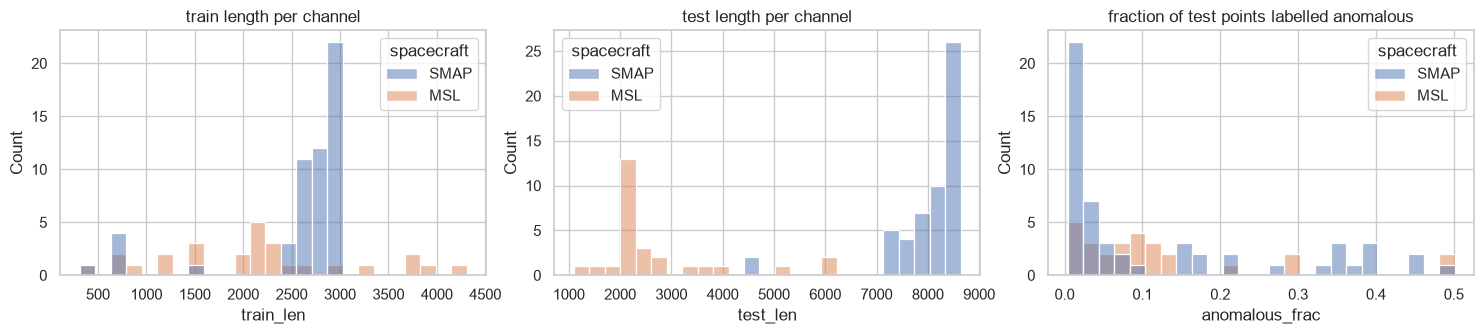

In [3]:
fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
sns.histplot(info, x="train_len", hue="spacecraft", ax=ax[0], bins=25); ax[0].set_title("train length per channel")
sns.histplot(info, x="test_len", hue="spacecraft", ax=ax[1], bins=25); ax[1].set_title("test length per channel")
sns.histplot(info, x="anomalous_frac", hue="spacecraft", ax=ax[2], bins=25); ax[2].set_title("fraction of test points labelled anomalous")
fig.tight_layout(); fig.savefig(FIG / "eda_lengths_and_imbalance.png", dpi=110)
overall = (info.anomalous_frac * info.test_len).sum() / info.test_len.sum()
print("overall anomalous fraction of test points: %.3f" % overall)

**So what:**
* Test files are typically *longer* than train files - models learn from little history.
* Roughly 1 in 8 test points is labelled anomalous overall, but most channels are far more imbalanced.
  A model that always says "normal" would score ~87% accuracy -> we report precision/recall/F1/FPR, not accuracy.
* Channels are short (a few thousand points), which bounds how big an LSTM we can justify.

## 2. Look at real channels: train vs test, with labels

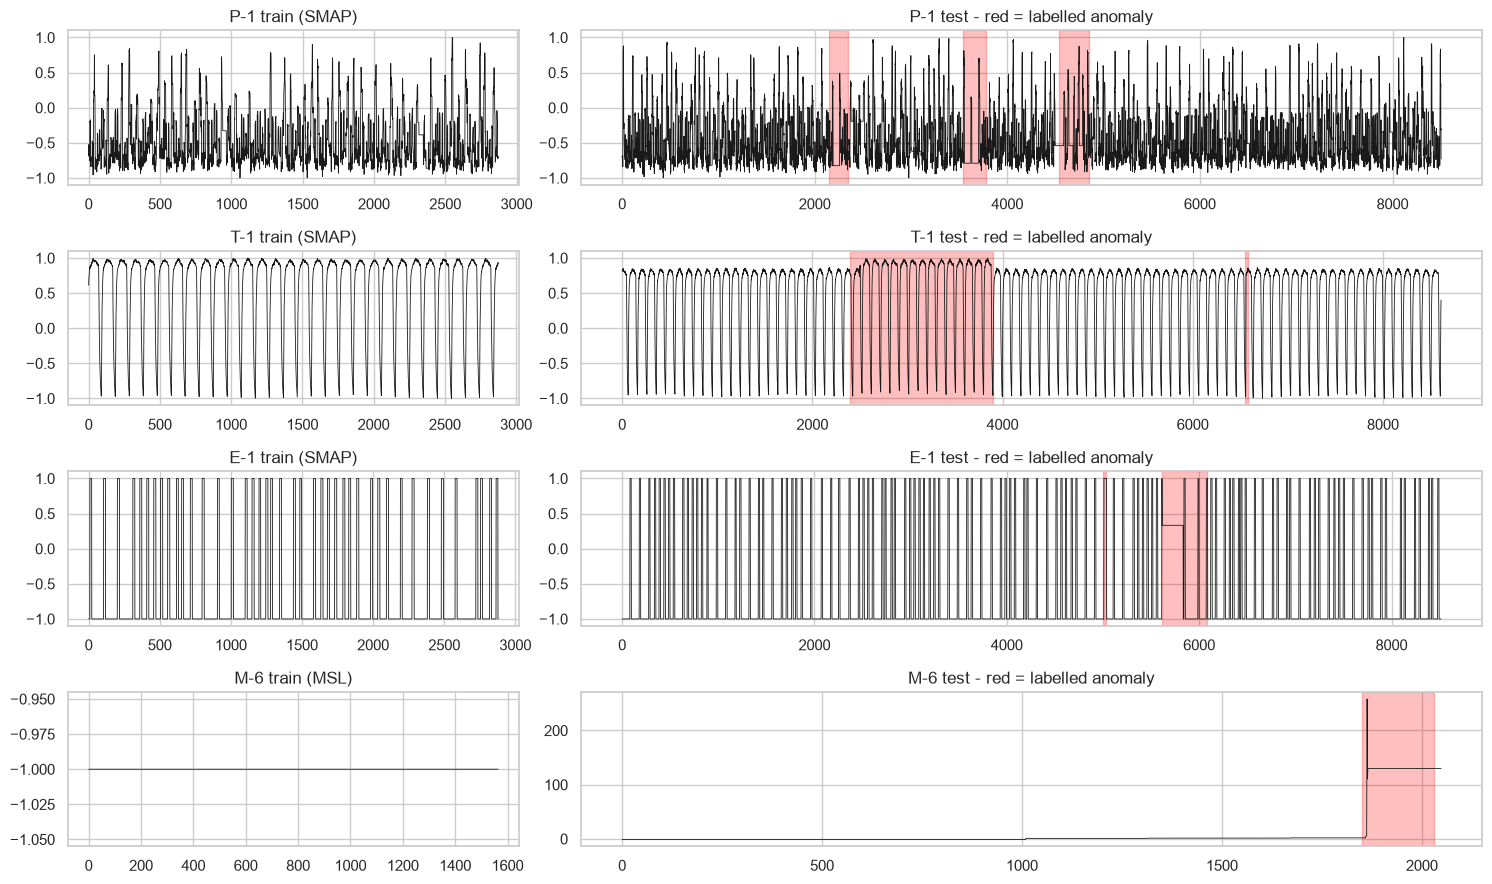

In [4]:
def show(chan, ax_row):
    r = labels.set_index("chan_id").loc[chan]
    tr, te = load_channel(RAW, chan, "train"), load_channel(RAW, chan, "test")
    ax_row[0].plot(tr[:, 0], lw=.6, c="k"); ax_row[0].set_title(f"{chan} train ({r.spacecraft})")
    ax_row[1].plot(te[:, 0], lw=.6, c="k"); ax_row[1].set_title(f"{chan} test - red = labelled anomaly")
    for (s, e), cls in zip(r.anomaly_sequences, r.classes):
        ax_row[1].axvspan(s, e, color="red", alpha=.25)
fig, axes = plt.subplots(4, 2, figsize=(15, 9), gridspec_kw=dict(width_ratios=[1, 2]))
for chan, row in zip(["P-1", "T-1", "E-1", "M-6"], axes):
    show(chan, row)
fig.tight_layout(); fig.savefig(FIG / "eda_example_channels.png", dpi=110)

**So what:** behaviour ranges from smooth periodic signals to piecewise-constant "mode" signals.
A single global z-score threshold would not suit all of them -> models and thresholds are **per channel**.
M-6 is flat in training and jumps to very large values in test: anything that changes looks anomalous.

## 3. Constant training channels and train/test distribution shift

19 of 81 channels have a constant telemetry value in TRAIN: ['A-1', 'D-2', 'G-2', 'D-5', 'D-7', 'P-4', 'D-8', 'D-9', 'D-12', 'B-1', 'R-1', 'A-5', 'D-13', 'M-6', 'S-2', 'T-5', 'C-2', 'D-14', 'P-14']


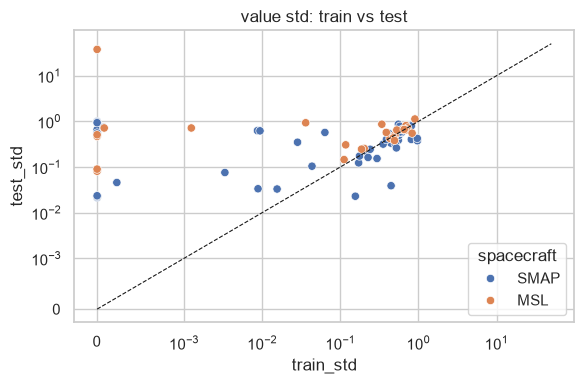

In [5]:
const = info[info.train_std < 1e-3]
print(f"{len(const)} of {len(info)} channels have a constant telemetry value in TRAIN:", const.chan_id.tolist())
fig, ax = plt.subplots(figsize=(6, 4))
sns.scatterplot(info, x="train_std", y="test_std", hue="spacecraft", ax=ax)
ax.set_xscale("symlog", linthresh=1e-3); ax.set_yscale("symlog", linthresh=1e-3)
ax.plot([0, 50], [0, 50], "k--", lw=.8); ax.set_title("value std: train vs test")
fig.tight_layout(); fig.savefig(FIG / "eda_train_test_std.png", dpi=110)

**So what:** ~a quarter of channels carry no variation in training, so a scaler fitted on train would divide by zero.
`ValueScaler` falls back to std = 1 for those channels (documented). Many channels are noticeably more variable in test
than in train (points above the dashed line): **distribution shift** is part of the problem, and some "anomalies" will
simply be regimes never seen in training. This is a key limitation of learning "normal" from short histories.

## 4. Anomaly events: how long are they?

            count   mean     std   min    25%    50%    75%     max
cls                                                                
contextual   43.0  479.0   882.0  31.0  101.0  121.0  305.0  3865.0
point        61.0  707.0  1117.0  11.0   69.0  121.0  641.0  4218.0


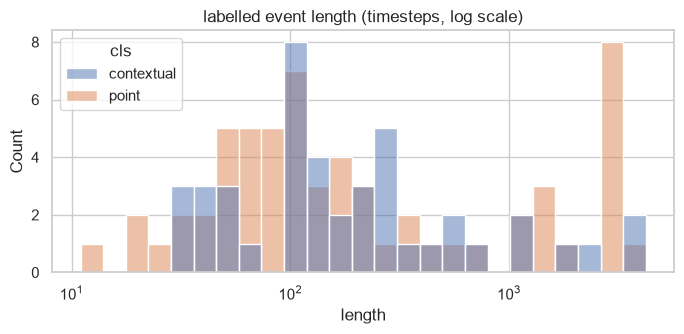

In [6]:
ev = pd.DataFrame([dict(chan_id=r.chan_id, spacecraft=r.spacecraft, cls=c, length=e - s + 1)
                   for r in labels.itertuples() for (s, e), c in zip(r.anomaly_sequences, r.classes)])
print(ev.groupby("cls").length.describe().round(0))
fig, ax = plt.subplots(figsize=(7, 3.5))
sns.histplot(ev, x="length", hue="cls", log_scale=True, bins=25, ax=ax); ax.set_title("labelled event length (timesteps, log scale)")
fig.tight_layout(); fig.savefig(FIG / "eda_event_lengths.png", dpi=110)

**So what:** events span from tens to thousands of timesteps. In *point-wise* metrics a few long events dominate,
so we also report **event-wise** metrics where each labelled sequence counts once. Note the benchmark's "point" class
refers to anomaly *type* (an unusual value), not to events of length 1.

## 5. Command features and temporal dependence

            count   mean    std    min    25%    50%    75%    max
spacecraft                                                        
MSL          27.0  0.307  0.211  0.047  0.122  0.284  0.430  0.704
SMAP         54.0  0.129  0.074  0.000  0.042  0.177  0.182  0.207


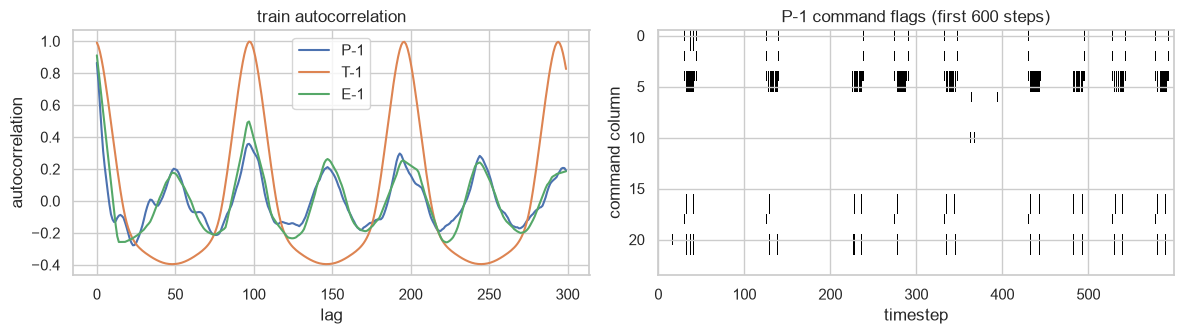

In [7]:
print(info.groupby("spacecraft").train_cmd_rate.describe().round(3))
from pandas.plotting import autocorrelation_plot
fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
for chan in ["P-1", "T-1", "E-1"]:
    v = pd.Series(load_channel(RAW, chan, "train")[:, 0])
    ax[0].plot([v.autocorr(l) for l in range(1, 301)], label=chan)
ax[0].set_xlabel("lag"); ax[0].set_ylabel("autocorrelation"); ax[0].legend(); ax[0].set_title("train autocorrelation")
tr = load_channel(RAW, "P-1", "train")
ax[1].imshow(tr[:600, 1:].T, aspect="auto", cmap="Greys", interpolation="nearest")
ax[1].set_title("P-1 command flags (first 600 steps)"); ax[1].set_xlabel("timestep"); ax[1].set_ylabel("command column")
fig.tight_layout(); fig.savefig(FIG / "eda_autocorr_commands.png", dpi=110)

**So what:** strong autocorrelation over long lags means the past is informative about the next value -
the premise of a forecasting model. A window of 100 steps covers much of the dependence structure while keeping CPU
cost reasonable (the original paper used 250). Command flags are sparse 0/1 events; the LSTM receives them as inputs so
that commanded changes are less surprising than spontaneous ones.

## 6. Data quality summary
Full checks live in `src/data/validation.py` (results in `reports/data_validation.json`):

In [8]:
v = json.loads((ROOT / "reports/data_validation.json").read_text())
print("ok:", v["ok"], "| errors:", v["errors"])
for w in v["warnings"]: print("-", w[:140])

ok: True | errors: []
- P-2: 2 label rows [[[5350, 6575]], [[5300, 6420]]] merged into their interval union
- Telemetry files with no label row (excluded from evaluation): ['T-10']
- M-6: test values in [-1, 258], outside the documented [-1, 1] range
- M-1: test values in [-1.08, 2.27], outside the documented [-1, 1] range
- M-2: test values in [-1.08, 1.34], outside the documented [-1, 1] range
- M-3: test values in [-1.42, 1], outside the documented [-1, 1] range
- M-4: test values in [-1.33, 1.18], outside the documented [-1, 1] range
- M-5: test values in [-1.31, 1.1], outside the documented [-1, 1] range
- F-4: test values in [-1, 1.47], outside the documented [-1, 1] range
- F-5: test values in [-1.08, 6.95], outside the documented [-1, 1] range
- T-8: test values in [-1, 1.02], outside the documented [-1, 1] range
- D-15: test values in [-1, 1.38], outside the documented [-1, 1] range
- F-8: test values in [-1, 1.3], outside the documented [-1, 1] range
- 19 channels have a cons

## Decisions this EDA supports
| Observation | Decision |
|---|---|
| Strong class imbalance | Precision / recall / F1 / FPR + event metrics; never accuracy alone |
| Heterogeneous channels | One model and one threshold per channel |
| Constant train channels | Scaler std fallback; flag in docs; expect many false alarms there |
| Long-range autocorrelation | Window-based models; LSTM forecaster with W = 100 |
| Train/test shift, test-based pre-scaling by dataset authors | Documented limitations, can't be fixed downstream |
| Labels only for test | Thresholds calibrated on the last 20% of TRAIN (no labels used) |